# **Supermarket Sales Analysis**

Using pandas , numpy, matplotlib.pylot and seaborn libraries.

**Step 1: Import the required libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

**Step 2: Load the dataset**

In [2]:
df=pd.read_csv('/content/supermarket_sales.csv')
print('dataset loaded successfully!')
print('Dataset Shape:',df.shape)

df.head()

dataset loaded successfully!
Dataset Shape: (1000, 9)


,Invoice ID,Date,Product,Category,Quantity,Unit Price,Customer Type,Payment,Total
0,1001,2023-01-11,Cap,Clothing,8,51.19,Normal,Credit Card,409.52
1,1002,2023-01-07,Milk,Beverages,7,3.12,Member,Cash,21.84
2,1003,2023-01-17,Soap,Household,10,23.87,Member,Digital Payment,238.70
3,1004,2023-01-21,Mouse,Electronics,10,53.81,Normal,Cash,538.10
4,1005,2023-01-09,Apples,Food,8,1.37,Member,Credit Card,10.96




**Step 3: Check the number of rows and columns**

In [3]:
print('Number of rows:',df.shape[0])
print('Number of columns:',df.shape[1])

Number of rows: 1000
Number of columns: 9


In [4]:
print('Coulmn Names: ')
print(df.columns.tolist())

Coulmn Names: 
['Invoice ID', 'Date', 'Product', 'Category', 'Quantity', 'Unit Price', 'Customer Type', 'Payment', 'Total']


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Invoice ID     1000 non-null   int64  
 1   Date           1000 non-null   object 
 2   Product        1000 non-null   object 
 3   Category       1000 non-null   object 
 4   Quantity       1000 non-null   int64  
 5   Unit Price     1000 non-null   float64
 6   Customer Type  1000 non-null   object 
 7   Payment        1000 non-null   object 
 8   Total          1000 non-null   float64
dtypes: float64(2), int64(2), object(5)
memory usage: 70.4+ KB


In [6]:
df.describe()

,Invoice ID,Quantity,Unit Price,Total
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,1500.500000,5.525000,14.800810,81.902280
std,288.819436,2.850877,18.235187,120.167821
min,1001.000000,1.000000,0.520000,0.760000
25%,1250.750000,3.000000,3.250000,13.432500
50%,1500.500000,5.500000,5.935000,31.780000
75%,1750.250000,8.000000,20.047500,86.625000
max,2000.000000,10.000000,79.980000,799.800000


In [7]:
df.sample(5)

,Invoice ID,Date,Product,Category,Quantity,Unit Price,Customer Type,Payment,Total
792,1793,2023-01-10,Apples,Food,3,6.05,Member,Cash,18.15
703,1704,2023-01-24,Brush,Household,10,20.50,Normal,Cash,205.00
433,1434,2023-01-12,Jeans,Clothing,4,22.06,Member,Cash,88.24
393,1394,2023-01-14,Headphones,Electronics,2,5.82,Member,Credit Card,11.64
706,1707,2023-01-20,Jacket,Clothing,2,53.98,Member,Cash,107.96


**Step 4: Check for missing values**

In [8]:
print('Missing values in each column:')
print(df.isnull().sum())

Missing values in each column:
Invoice ID       0
Date             0
Product          0
Category         0
Quantity         0
Unit Price       0
Customer Type    0
Payment          0
Total            0
dtype: int64


**Check for duplicates and remove the duplicated records**

In [10]:
print('Number of duplicated rows:', df.duplicated().sum())

df=df.drop_duplicates()
print('Dataset shape after removing duplicates:',df.shape)

Number of duplicated rows: 0
Dataset shape after removing duplicates: (1000, 9)


**Step 5: Convert Date Column**

To analyze sales by date, we need to make sure Date column uses a proper date format.

In [11]:
df['Date']=pd.to_datetime(df['Date'],errors='coerce')
print(df['Date'].dtype)

datetime64[ns]


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Invoice ID     1000 non-null   int64         
 1   Date           1000 non-null   datetime64[ns]
 2   Product        1000 non-null   object        
 3   Category       1000 non-null   object        
 4   Quantity       1000 non-null   int64         
 5   Unit Price     1000 non-null   float64       
 6   Customer Type  1000 non-null   object        
 7   Payment        1000 non-null   object        
 8   Total          1000 non-null   float64       
dtypes: datetime64[ns](1), float64(2), int64(2), object(4)
memory usage: 70.4+ KB


**Step 6.1 : Calculate total sales**

In [13]:
total_sales=df['Total'].sum()

print('Total Sales:',round(total_sales,2))

Total Sales: 81902.28


**Step 6.2 : Calculate average sales**

In [14]:
average_sales=df['Total'].mean()

print('Average Sales per Transaction:', round(average_sales,2))


Average Sales per Transaction: 81.9


**Step 6.3 : Find the highest andd lowest sales**

In [15]:
highest_sale=df['Total'].max()
lowest_sale=df['Total'].min()

print('Highest Sale:',round(highest_sale,2))
print('Lowest Sale:',round(lowest_sale,2))

Highest Sale: 799.8
Lowest Sale: 0.76


**Step 6.4 : Calculate total quantity sold**

In [16]:
total_quantity=df['Quantity'].sum()
print('Total Quantity Sold:',total_quantity)

Total Quantity Sold: 5525


**Step 6.5 : Analyze sales by product category**

In [18]:
category_sales=df.groupby('Product')['Total'].sum()

print('sales by product category:')
print(category_sales.sort_values(ascending=False))

sales by product category:
Product
Mouse         10012.07
USB Cable      7835.17
Charger        6470.39
Jeans          6343.23
Headphones     5719.01
Socks          5659.50
Jacket         4923.65
Cap            4714.81
Keyboard       4425.40
T-Shirt        3031.62
Soap           2369.17
Tissue         2351.30
Brush          2217.48
Biscuits       2033.55
Detergent      2006.36
Bread          1937.57
Cleaner        1646.73
Rice           1526.66
Eggs           1492.70
Apples         1397.44
Tea             860.42
Water           758.57
Milk            734.34
Juice           733.61
Coffee          701.53
Name: Total, dtype: float64


**Step 6.6 : Analyze sales by payment method**

In [19]:
payment_sales=df.groupby('Payment')['Total'].sum()

print('sales by payment method:')
print(payment_sales.sort_values(ascending=False))

sales by payment method:
Payment
Cash               41641.24
Credit Card        24125.90
Digital Payment    16135.14
Name: Total, dtype: float64


# Data Visualization

**Step 7.1 : Bar Chart - Sales by product category**

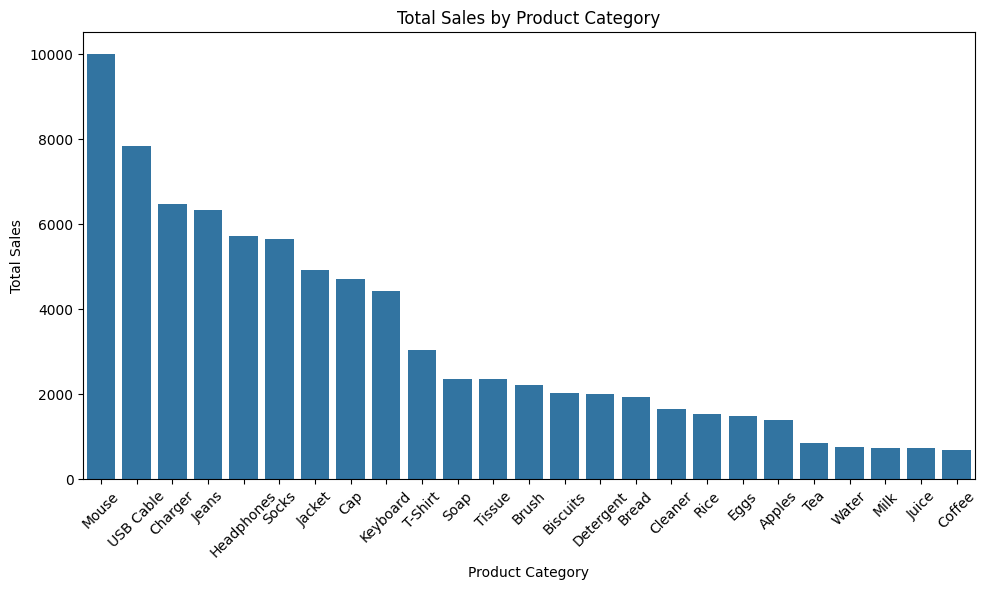

In [20]:
plt.figure(figsize=(10, 6))

category_sales = df.groupby("Product")["Total"].sum().sort_values(ascending=False)

sns.barplot(x=category_sales.index, y=category_sales.values)

plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Step 7.2 : Bar chart - Sales by payment method**

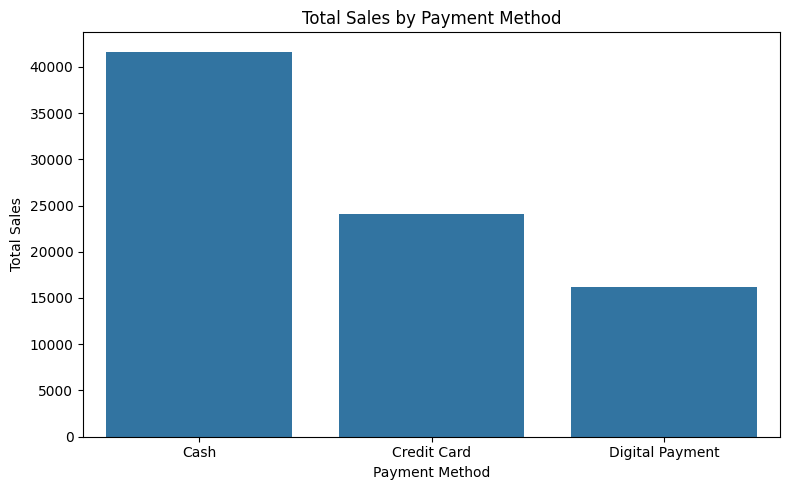

In [21]:
plt.figure(figsize=(8, 5))

payment_sales = df.groupby("Payment")["Total"].sum().sort_values(ascending=False)

sns.barplot(x=payment_sales.index, y=payment_sales.values)

plt.title("Total Sales by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

**Step 7.3: Pie chart - Customer type distribution**

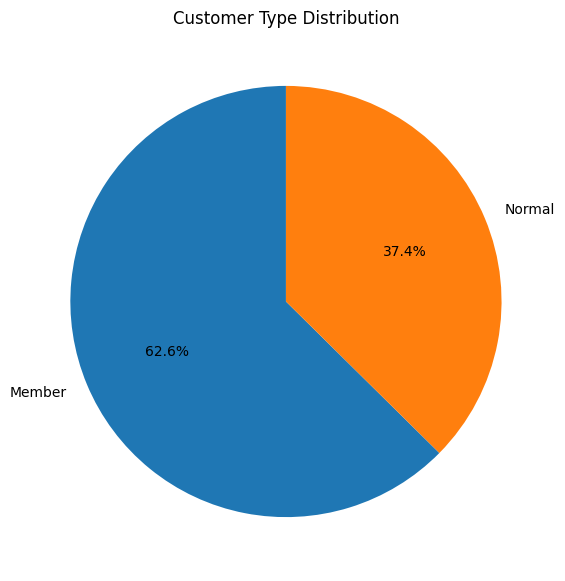

In [23]:
customer_counts = df["Customer Type"].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(
    customer_counts.values,
    labels=customer_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Customer Type Distribution")
plt.show()

**Step 7.4 : Line chart - Daily sales trend**

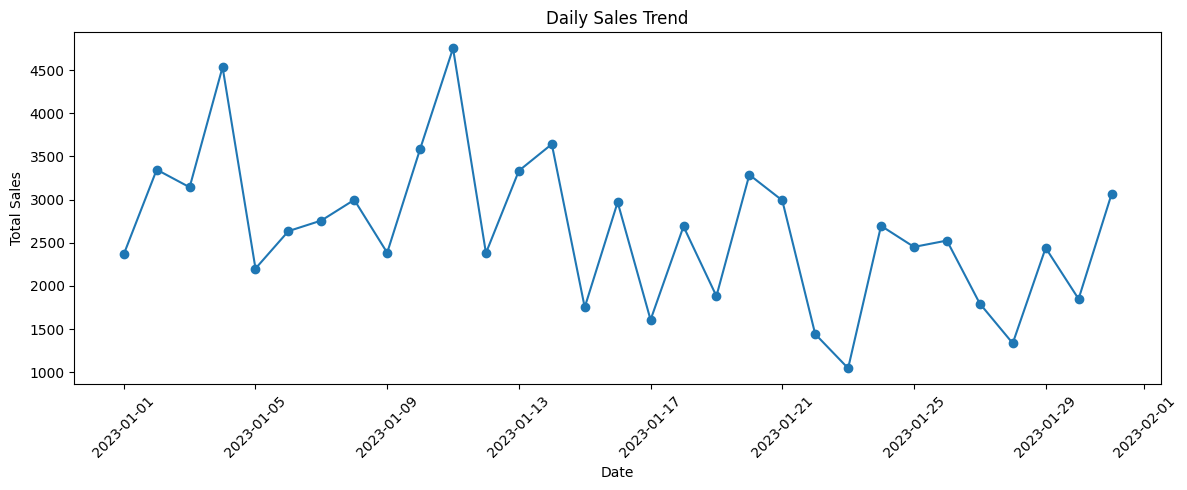

In [24]:
daily_sales = df.groupby("Date")["Total"].sum().sort_index()

plt.figure(figsize=(12, 5))
plt.plot(daily_sales.index, daily_sales.values, marker="o")

plt.title("Daily Sales Trend")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



**Step 8.1 : Analyze quantity sold by product category**

In [25]:
quantity_by_category = df.groupby("Product")["Quantity"].sum()

print("Quantity Sold by Product Category:")
print(quantity_by_category.sort_values(ascending=False))

Quantity Sold by Product Category:
Product
Biscuits      439
Bread         432
Rice          379
Eggs          339
Apples        337
Juice         235
Tea           234
Milk          233
Mouse         231
Brush         228
Water         221
Jeans         200
Coffee        199
Cap           178
Tissue        176
Soap          169
USB Cable     168
Charger       165
Socks         159
Headphones    147
Detergent     142
Cleaner       138
Jacket        137
Keyboard      131
T-Shirt       108
Name: Quantity, dtype: int64


**Step 8.2 : Analyze individual products**

In [28]:
product_sales = df.groupby("Product")["Total"].sum()

print("Top 10 Products by Sales:")
print(product_sales.sort_values(ascending=False).head(10))

Top 10 Products by Sales:
Product
Mouse         10012.07
USB Cable      7835.17
Charger        6470.39
Jeans          6343.23
Headphones     5719.01
Socks          5659.50
Jacket         4923.65
Cap            4714.81
Keyboard       4425.40
T-Shirt        3031.62
Name: Total, dtype: float64


**Step 9.1 — Extract the month from the Date column**

In [29]:

df["Month"] = df["Date"].dt.month

monthly_sales = df.groupby("Month")["Total"].sum()

print("Monthly Sales:")
print(monthly_sales)

Monthly Sales:
Month
1    81902.28
Name: Total, dtype: float64


**Step 9.2 — Visualize monthly sales**

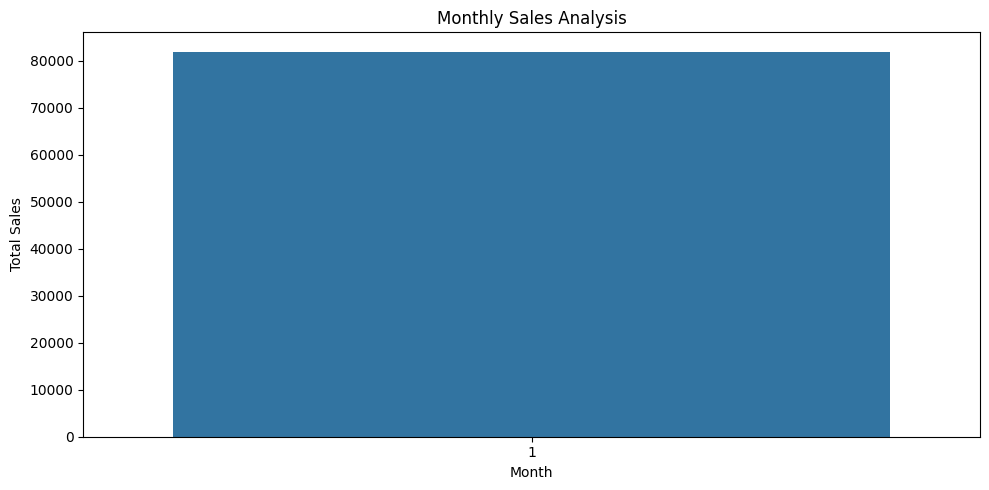

In [30]:
plt.figure(figsize=(10, 5))

sns.barplot(x=monthly_sales.index, y=monthly_sales.values)

plt.title("Monthly Sales Analysis")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

**Step 9.3 — Find the best sales month**

In [31]:
best_month = monthly_sales.idxmax()
highest_month_sales = monthly_sales.max()

print("Best Sales Month:", best_month)
print("Highest Monthly Sales:", round(highest_month_sales, 2))

Best Sales Month: 1
Highest Monthly Sales: 81902.28


**Step 9.4 — Analyze daily sales**

In [32]:
daily_sales = df.groupby("Date")["Total"].sum().sort_index()

print("Average Daily Sales:", round(daily_sales.mean(), 2))
print("Highest Daily Sales:", round(daily_sales.max(), 2))
print("Lowest Daily Sales:", round(daily_sales.min(), 2))

Average Daily Sales: 2642.01
Highest Daily Sales: 4753.16
Lowest Daily Sales: 1046.62


**Step 10 : Business Insights**

In [33]:

print("========== BUSINESS INSIGHTS ==========")

print("\n1. Total Sales:", round(df["Total"].sum(), 2))

print("\n2. Average Sales per Transaction:",
      round(df["Total"].mean(), 2))

print("\n3. Total Quantity Sold:",
      df["Quantity"].sum())

print("\n4. Best-Selling Category by Revenue:")
print(df.groupby("Category")["Total"].sum().idxmax())

print("\n5. Most Used Payment Method:")
print(df["Payment"].value_counts().idxmax())

print("\n6. Highest Revenue Customer Type:")
print(df.groupby("Customer Type")["Total"].sum().idxmax())

print("\n7. Best-Selling Product:")
print(df.groupby("Product")["Quantity"].sum().idxmax())

========== BUSINESS INSIGHTS ==========

1. Total Sales: 81902.28

2. Average Sales per Transaction: 81.9

3. Total Quantity Sold: 5525

4. Best-Selling Category by Revenue:
Electronics

5. Most Used Payment Method:
Cash

6. Highest Revenue Customer Type:
Member

7. Best-Selling Product:
Biscuits


**Conclusion**

The Supermarket Sales Data Analysis project was carried out using Python and its data analysis and visualization libraries, including Pandas, NumPy, Matplotlib, and Seaborn.

The dataset was explored and cleaned before performing exploratory data analysis (EDA). The analysis examined total sales, average transaction value, quantity sold, product category performance, payment methods, customer types, product sales, and monthly sales trends.

Various visualizations, including bar charts, pie charts, and line charts, were created to present the findings clearly. These visualizations help identify sales patterns, customer purchasing preferences, and product performance.

Overall, this project demonstrates how Python-based data analysis can transform raw supermarket transaction data into meaningful business insights that support better decision-making.